In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.cbook import boxplot_stats
import seaborn as sns
import os
from collections import Counter

In [32]:
relative_path = '/fasthome/a_makarova/article/box_plots'

files = ['unique_6genes1x_low_coverage_regions',
         'low_coverage_shared_regions', 
         'moderate_coverage_shared_regions',
         'high_coverage_shared_regions']

In [33]:
characteristics = ['GC-content', 'Length', 'Shannon Entropy for monomers',
                   'Mononucleotide repeat fraction', 'Dinucleotide repeat fraction', 
                   'Trinucleotide repeat fraction']

dfs = {}
for file in files:
    res_file=os.path.join(f'{relative_path}', f'{file}.tsv')
    df = pd.read_csv(res_file, sep='\t')
    dfs[file] = pd.DataFrame.copy(df, deep=False)


GC-content
Median: 0.39
95% CI: [0.39, 0.40]
Median: 0.35
95% CI: [0.34, 0.35]
Median: 0.39
95% CI: [0.38, 0.40]
Median: 0.43
95% CI: [0.42, 0.43]

Length
Median: 88.00
95% CI: [74.46, 101.54]
Median: 108.50
95% CI: [92.16, 124.84]
Median: 139.00
95% CI: [127.89, 150.11]
Median: 127.00
95% CI: [113.64, 140.36]

Shannon Entropy for monomers
Median: 1.95
95% CI: [1.94, 1.95]
Median: 1.91
95% CI: [1.90, 1.92]
Median: 1.95
95% CI: [1.94, 1.95]
Median: 1.96
95% CI: [1.96, 1.97]

Mononucleotide repeat fraction
Median: 0.00
95% CI: [-0.01, 0.01]
Median: 0.02
95% CI: [0.01, 0.03]
Median: 0.00
95% CI: [-0.00, 0.00]
Median: 0.00
95% CI: [-0.00, 0.00]

Dinucleotide repeat fraction
Median: 0.00
95% CI: [0.00, 0.00]
Median: 0.00
95% CI: [-0.00, 0.00]
Median: 0.00
95% CI: [-0.00, 0.00]
Median: 0.00
95% CI: [-0.00, 0.00]

Trinucleotide repeat fraction
Median: 0.00
95% CI: [0.00, 0.00]
Median: 0.00
95% CI: [0.00, 0.00]
Median: 0.00
95% CI: [0.00, 0.00]
Median: 0.00
95% CI: [0.00, 0.00]


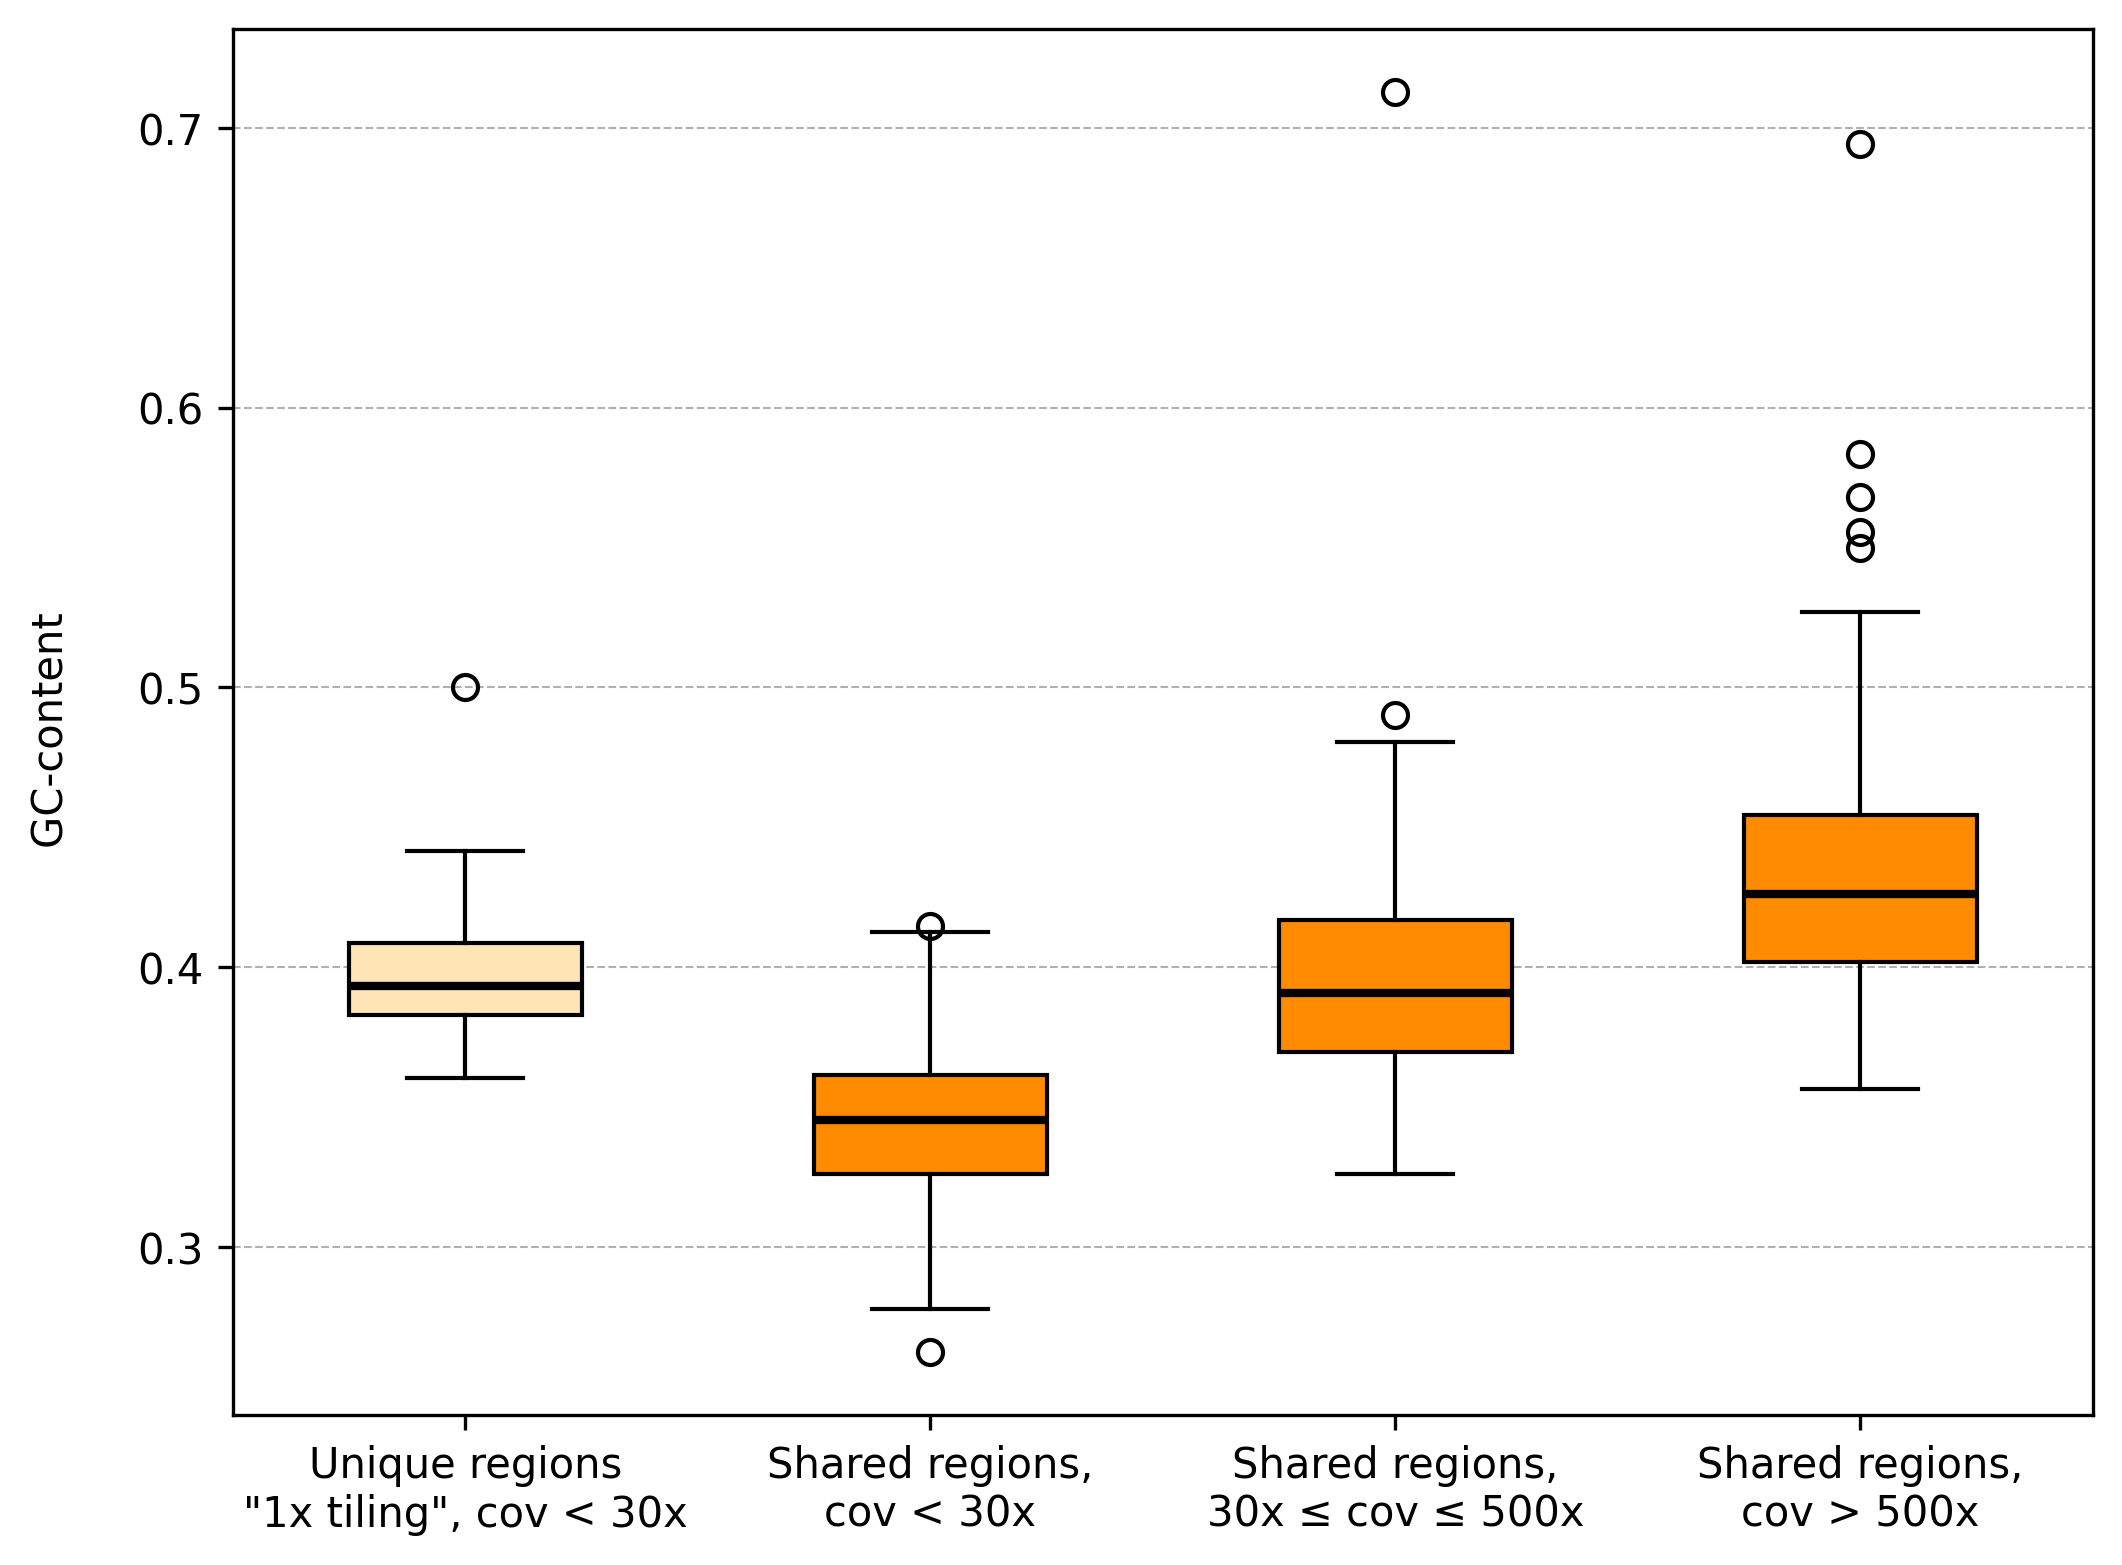

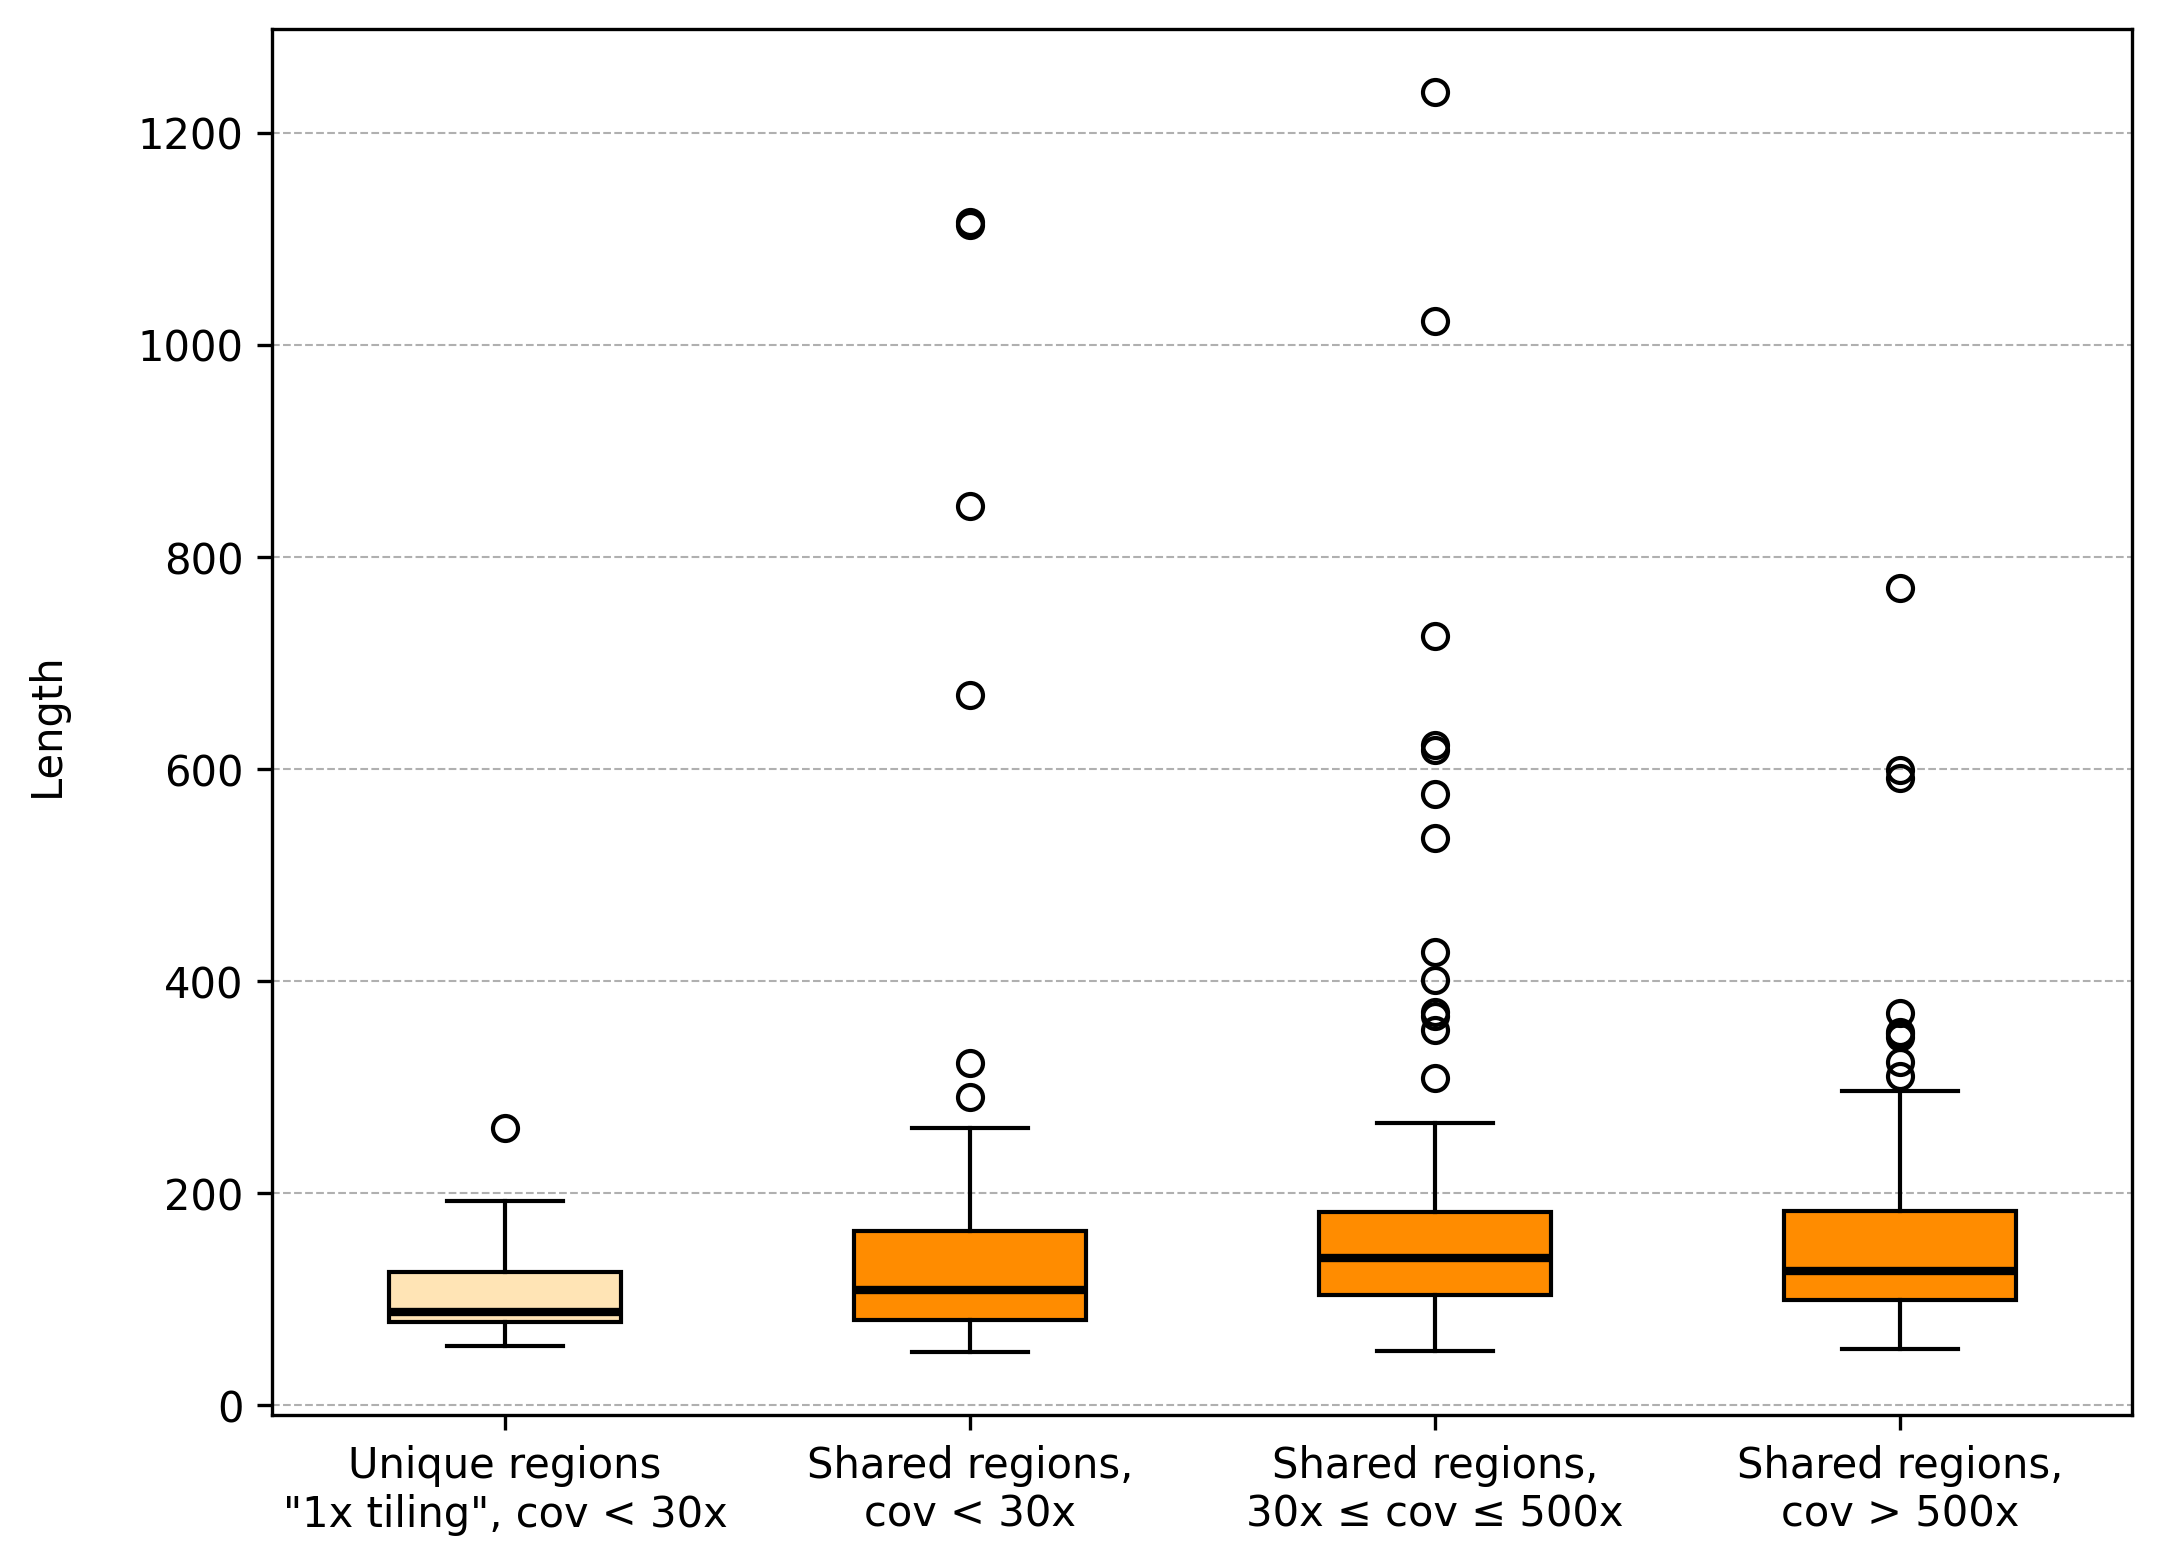

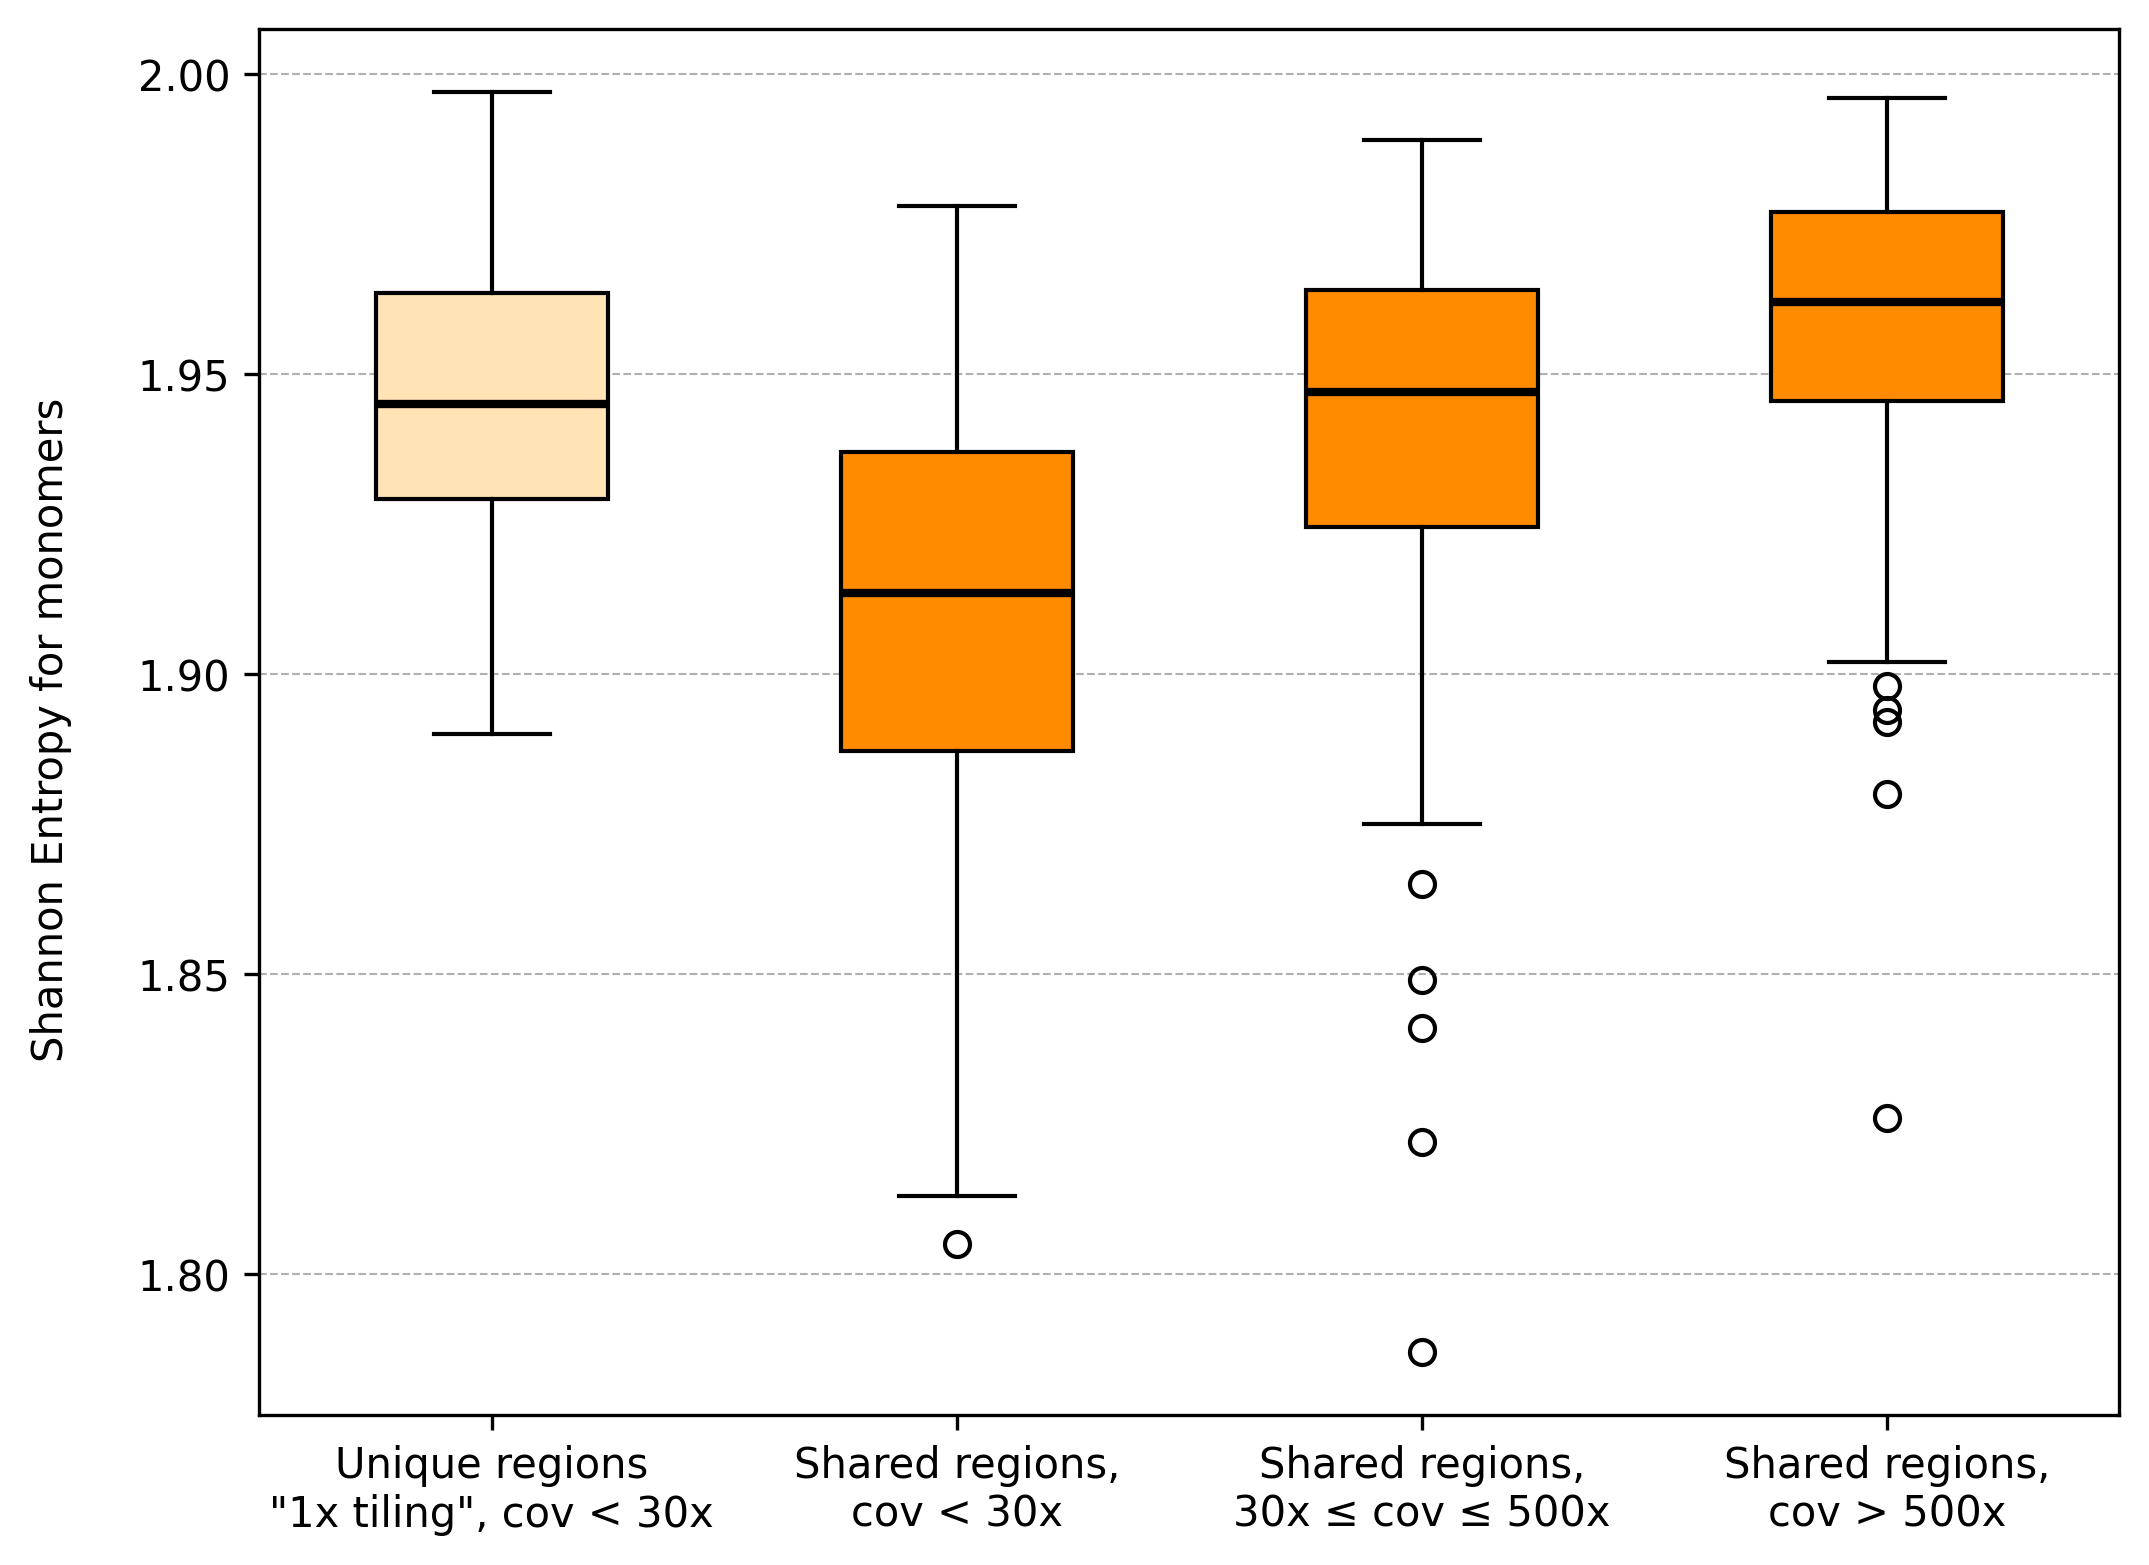

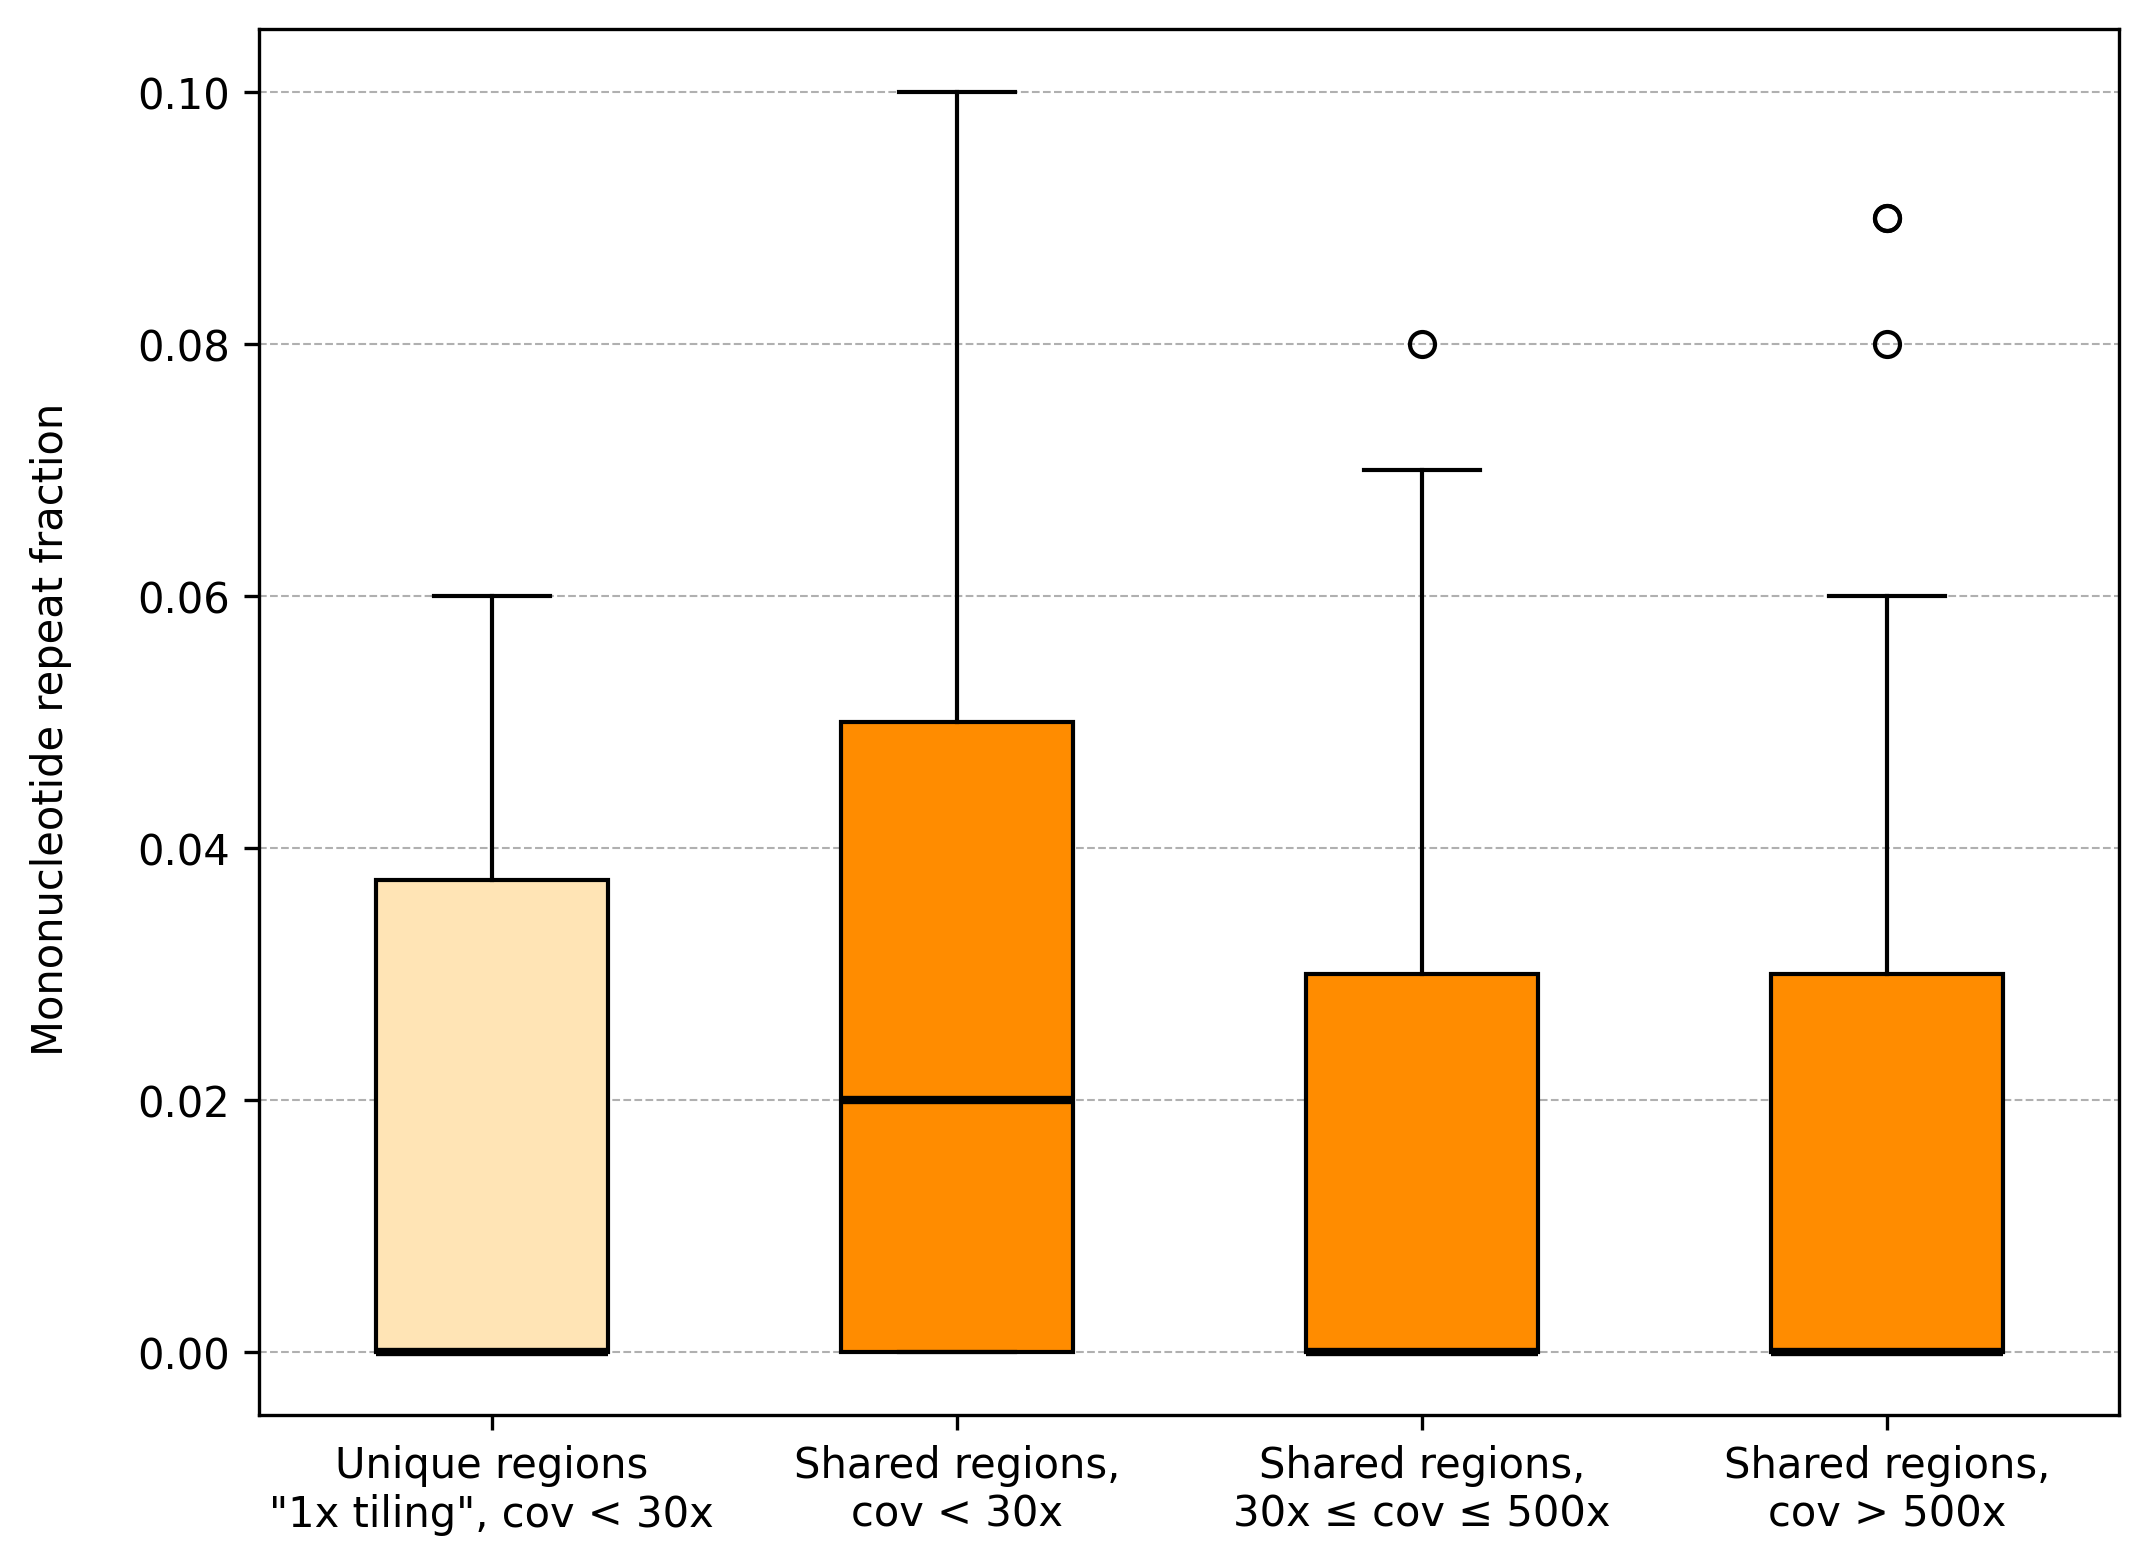

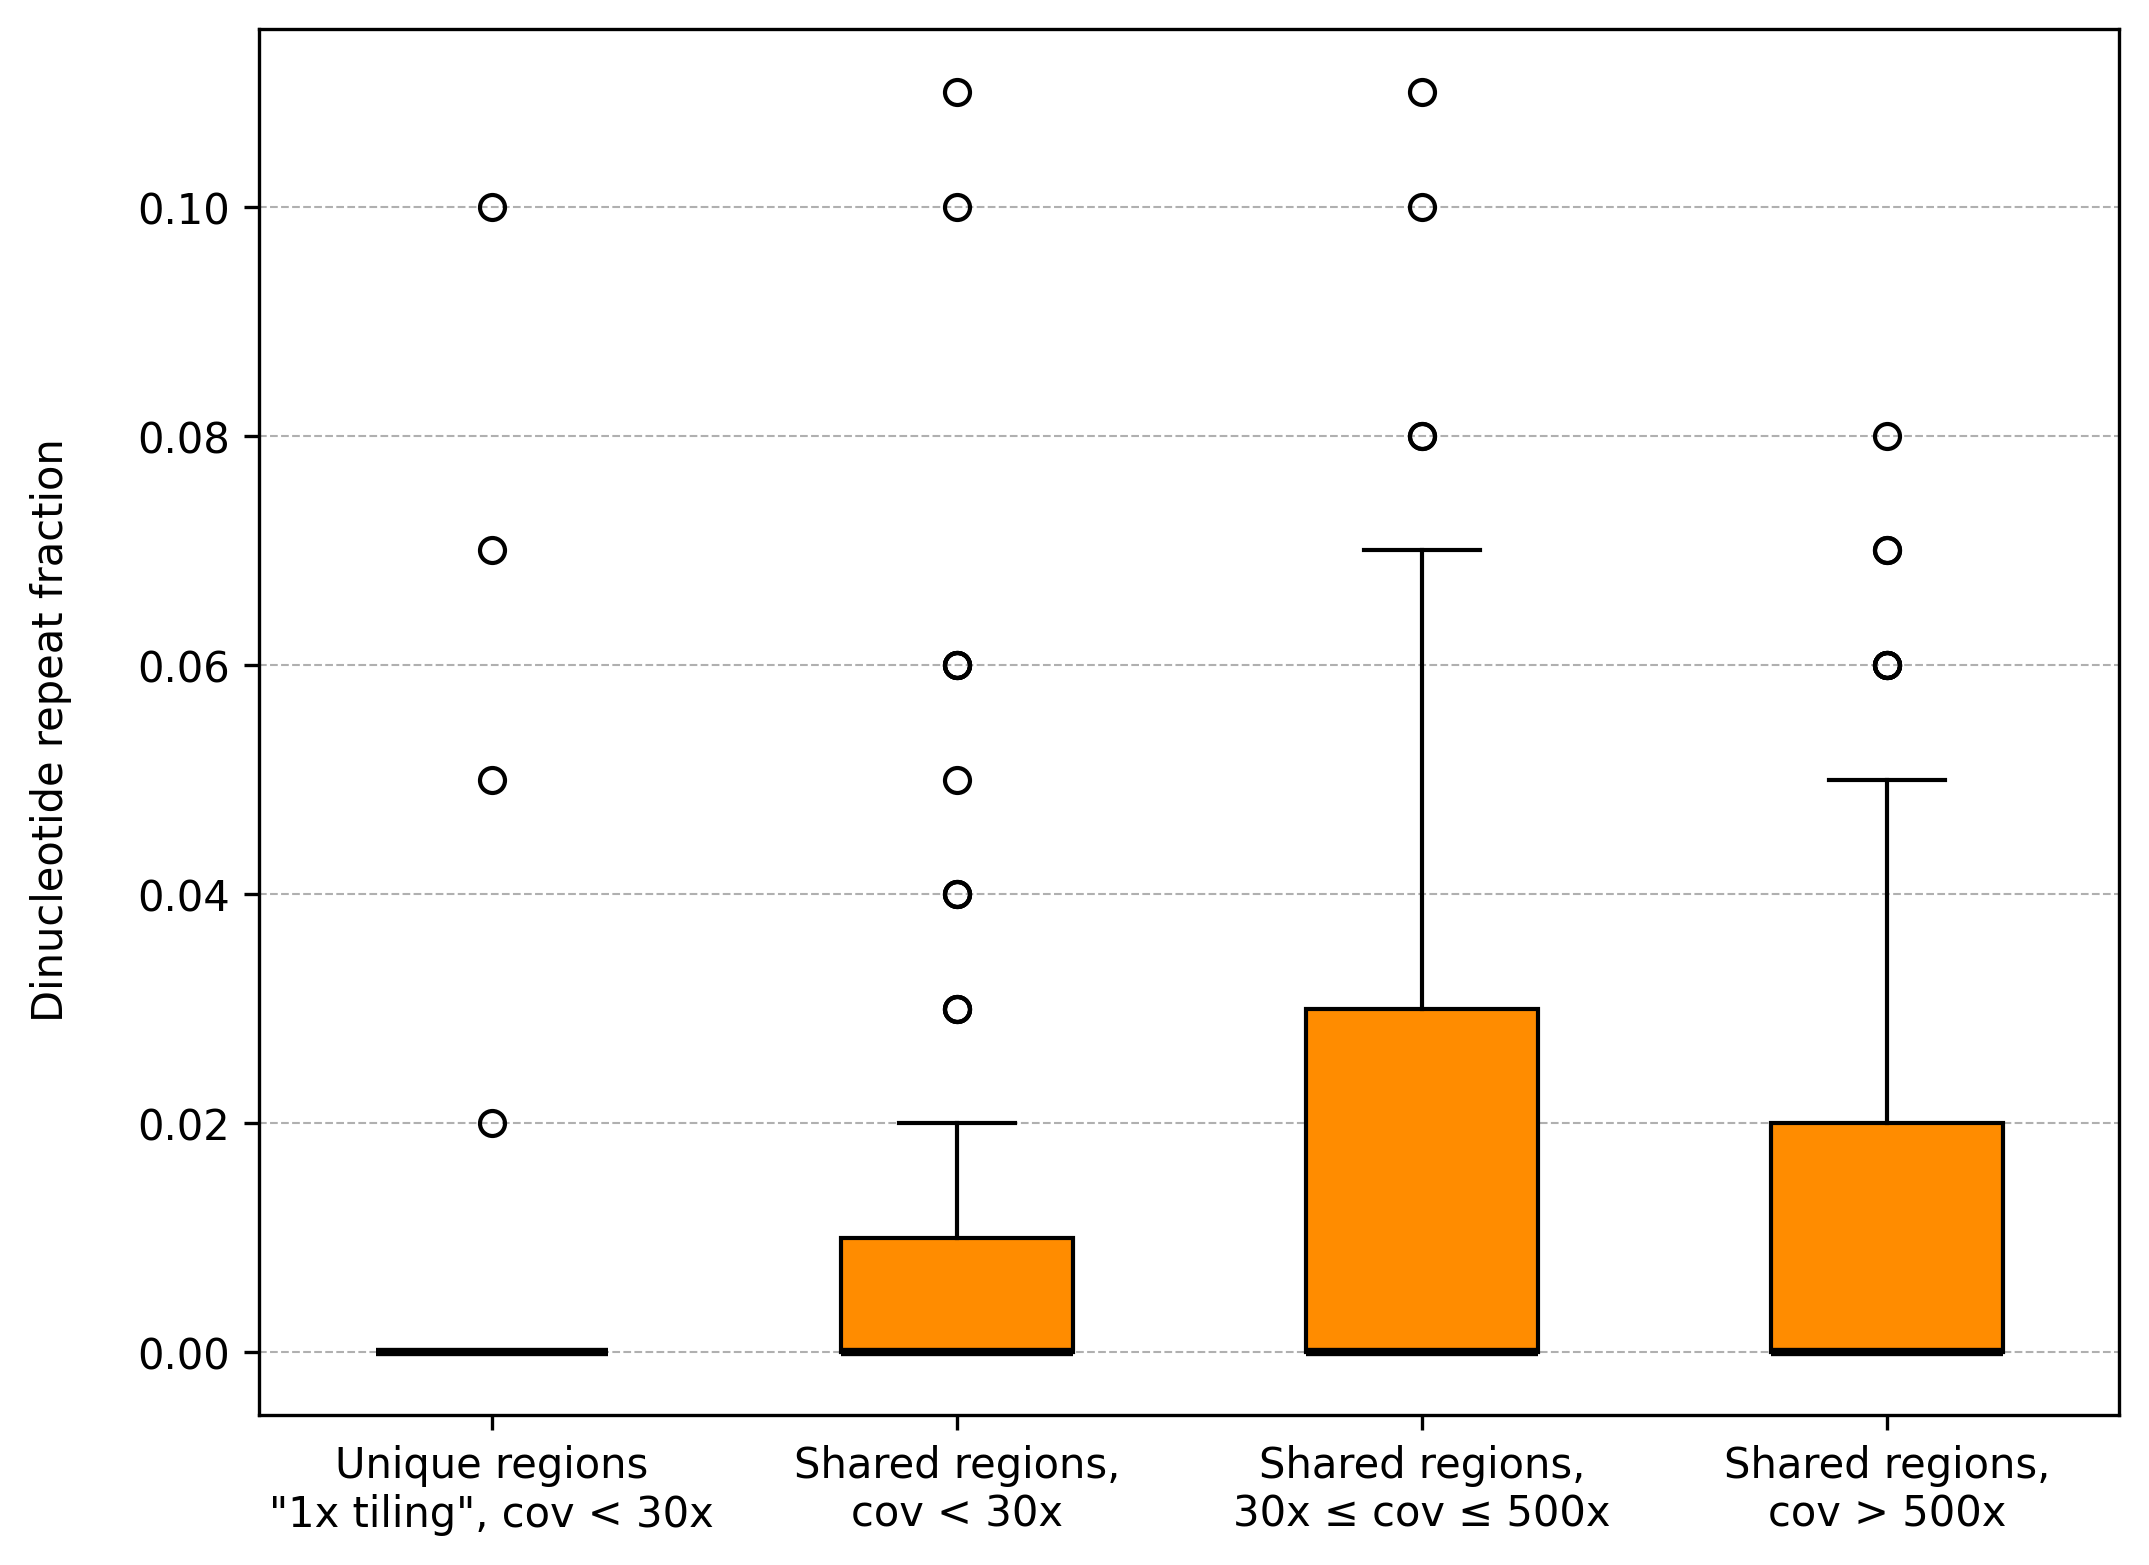

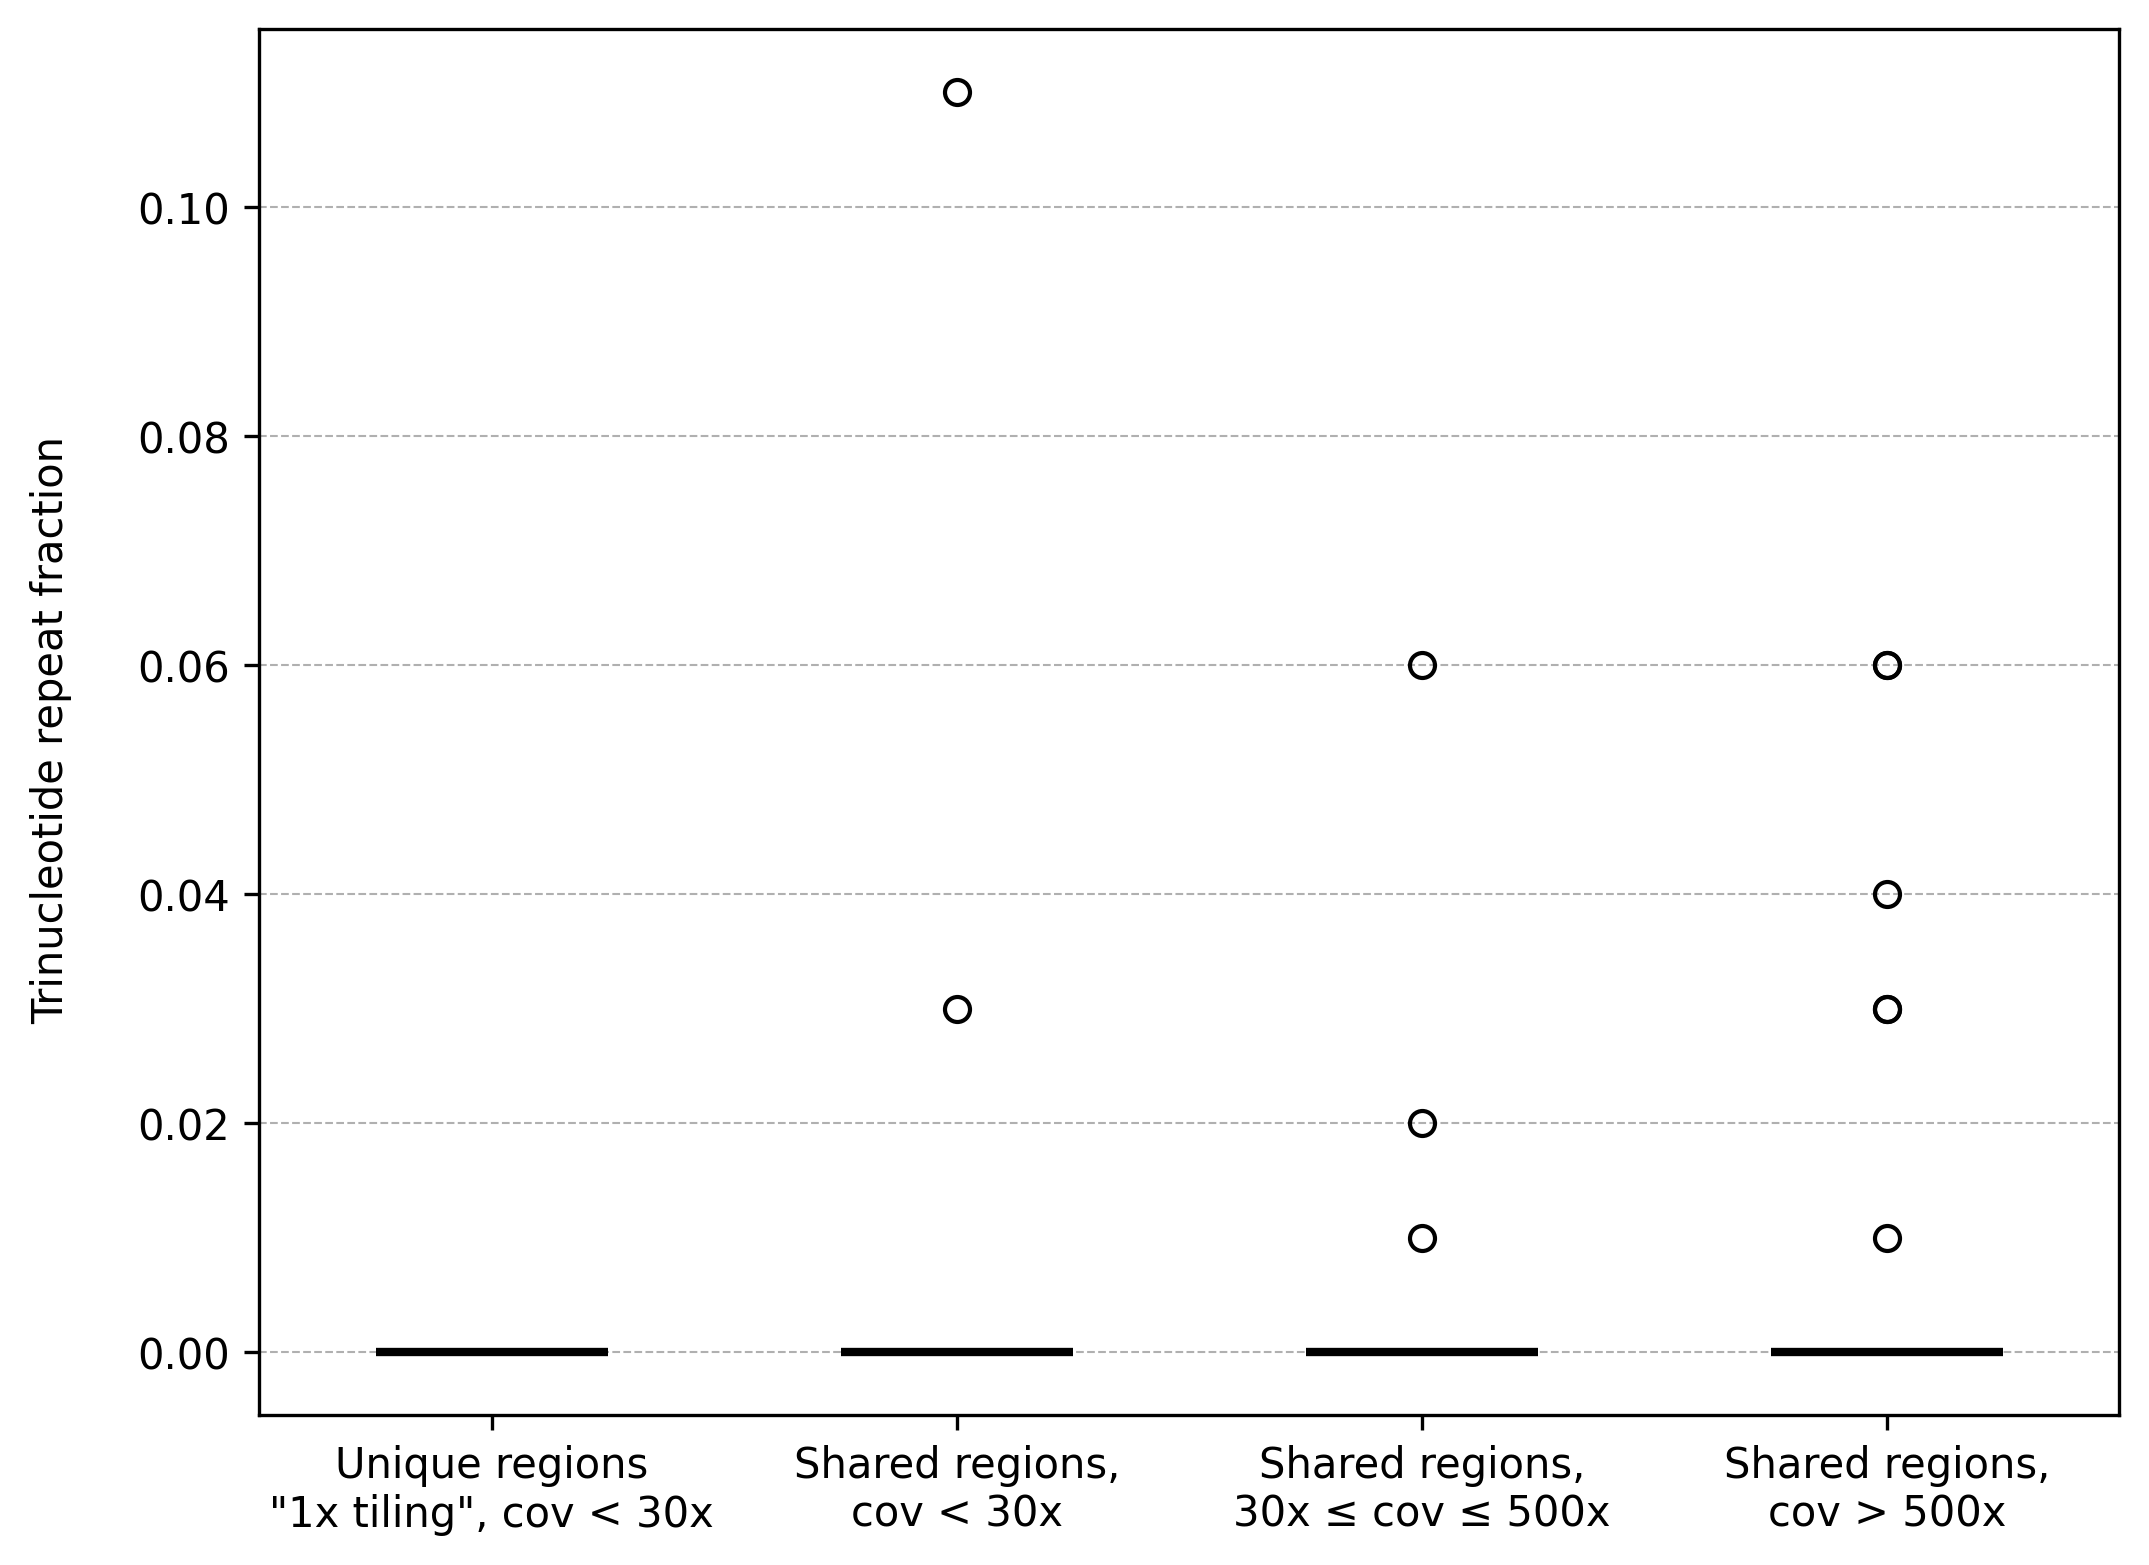

In [34]:
for i in range(len(characteristics)):
    print(f"\n{characteristics[i]}")
    fig, ax = plt.subplots(figsize=(8,6), dpi=300)
    colors = ['moccasin', 'darkorange', 'darkorange', 'darkorange']
    medians = dict(linewidth=2, color='black')
    ticks = [f'Unique regions\n"1x tiling", cov < 30x',
            f'Shared regions,\ncov < 30x',
            f'Shared regions,\n30x ≤ cov ≤ 500x',
            f'Shared regions,\ncov > 500x']

    bplot = ax.boxplot([dfs['unique_6genes1x_low_coverage_regions'][characteristics[i]], 
                        dfs['low_coverage_shared_regions'][characteristics[i]], 
                        dfs['moderate_coverage_shared_regions'][characteristics[i]],
                        dfs['high_coverage_shared_regions'][characteristics[i]]],
                        patch_artist=True, tick_labels=ticks,
                        widths=0.5, medianprops=medians)
    
    stats = boxplot_stats([
        dfs['unique_6genes1x_low_coverage_regions'][characteristics[i]], 
        dfs['low_coverage_shared_regions'][characteristics[i]], 
        dfs['moderate_coverage_shared_regions'][characteristics[i]],
        dfs['high_coverage_shared_regions'][characteristics[i]]
    ])
    for s in stats:
        print(f"Median: {s['med']:.2f}")
        print(f"95% CI: [{s['cilo']:.2f}, {s['cihi']:.2f}]")

    for patch, color in zip(bplot['boxes'], colors):
        patch.set_facecolor(color)

    ax.yaxis.grid(True, linestyle='--', linewidth=0.5)
    ax.set_ylabel(f"{characteristics[i]} \n")
    #plt.savefig(f'figs/{characteristics[i]}_boxplot.png', dpi=300)
    #plt.savefig(f'figs/svg/{characteristics[i]}_boxplot.svg')

In [35]:
df= pd.read_csv('compare_GC_lowcov_highcov.csv', sep='\t')
df=df.iloc[:,0:5]
df

FileNotFoundError: [Errno 2] No such file or directory: 'compare_GC_lowcov_highcov.csv'

Text(0.5, 1.0, 'ГЦ-состав участков, покрытых зондами Panel_New и China')

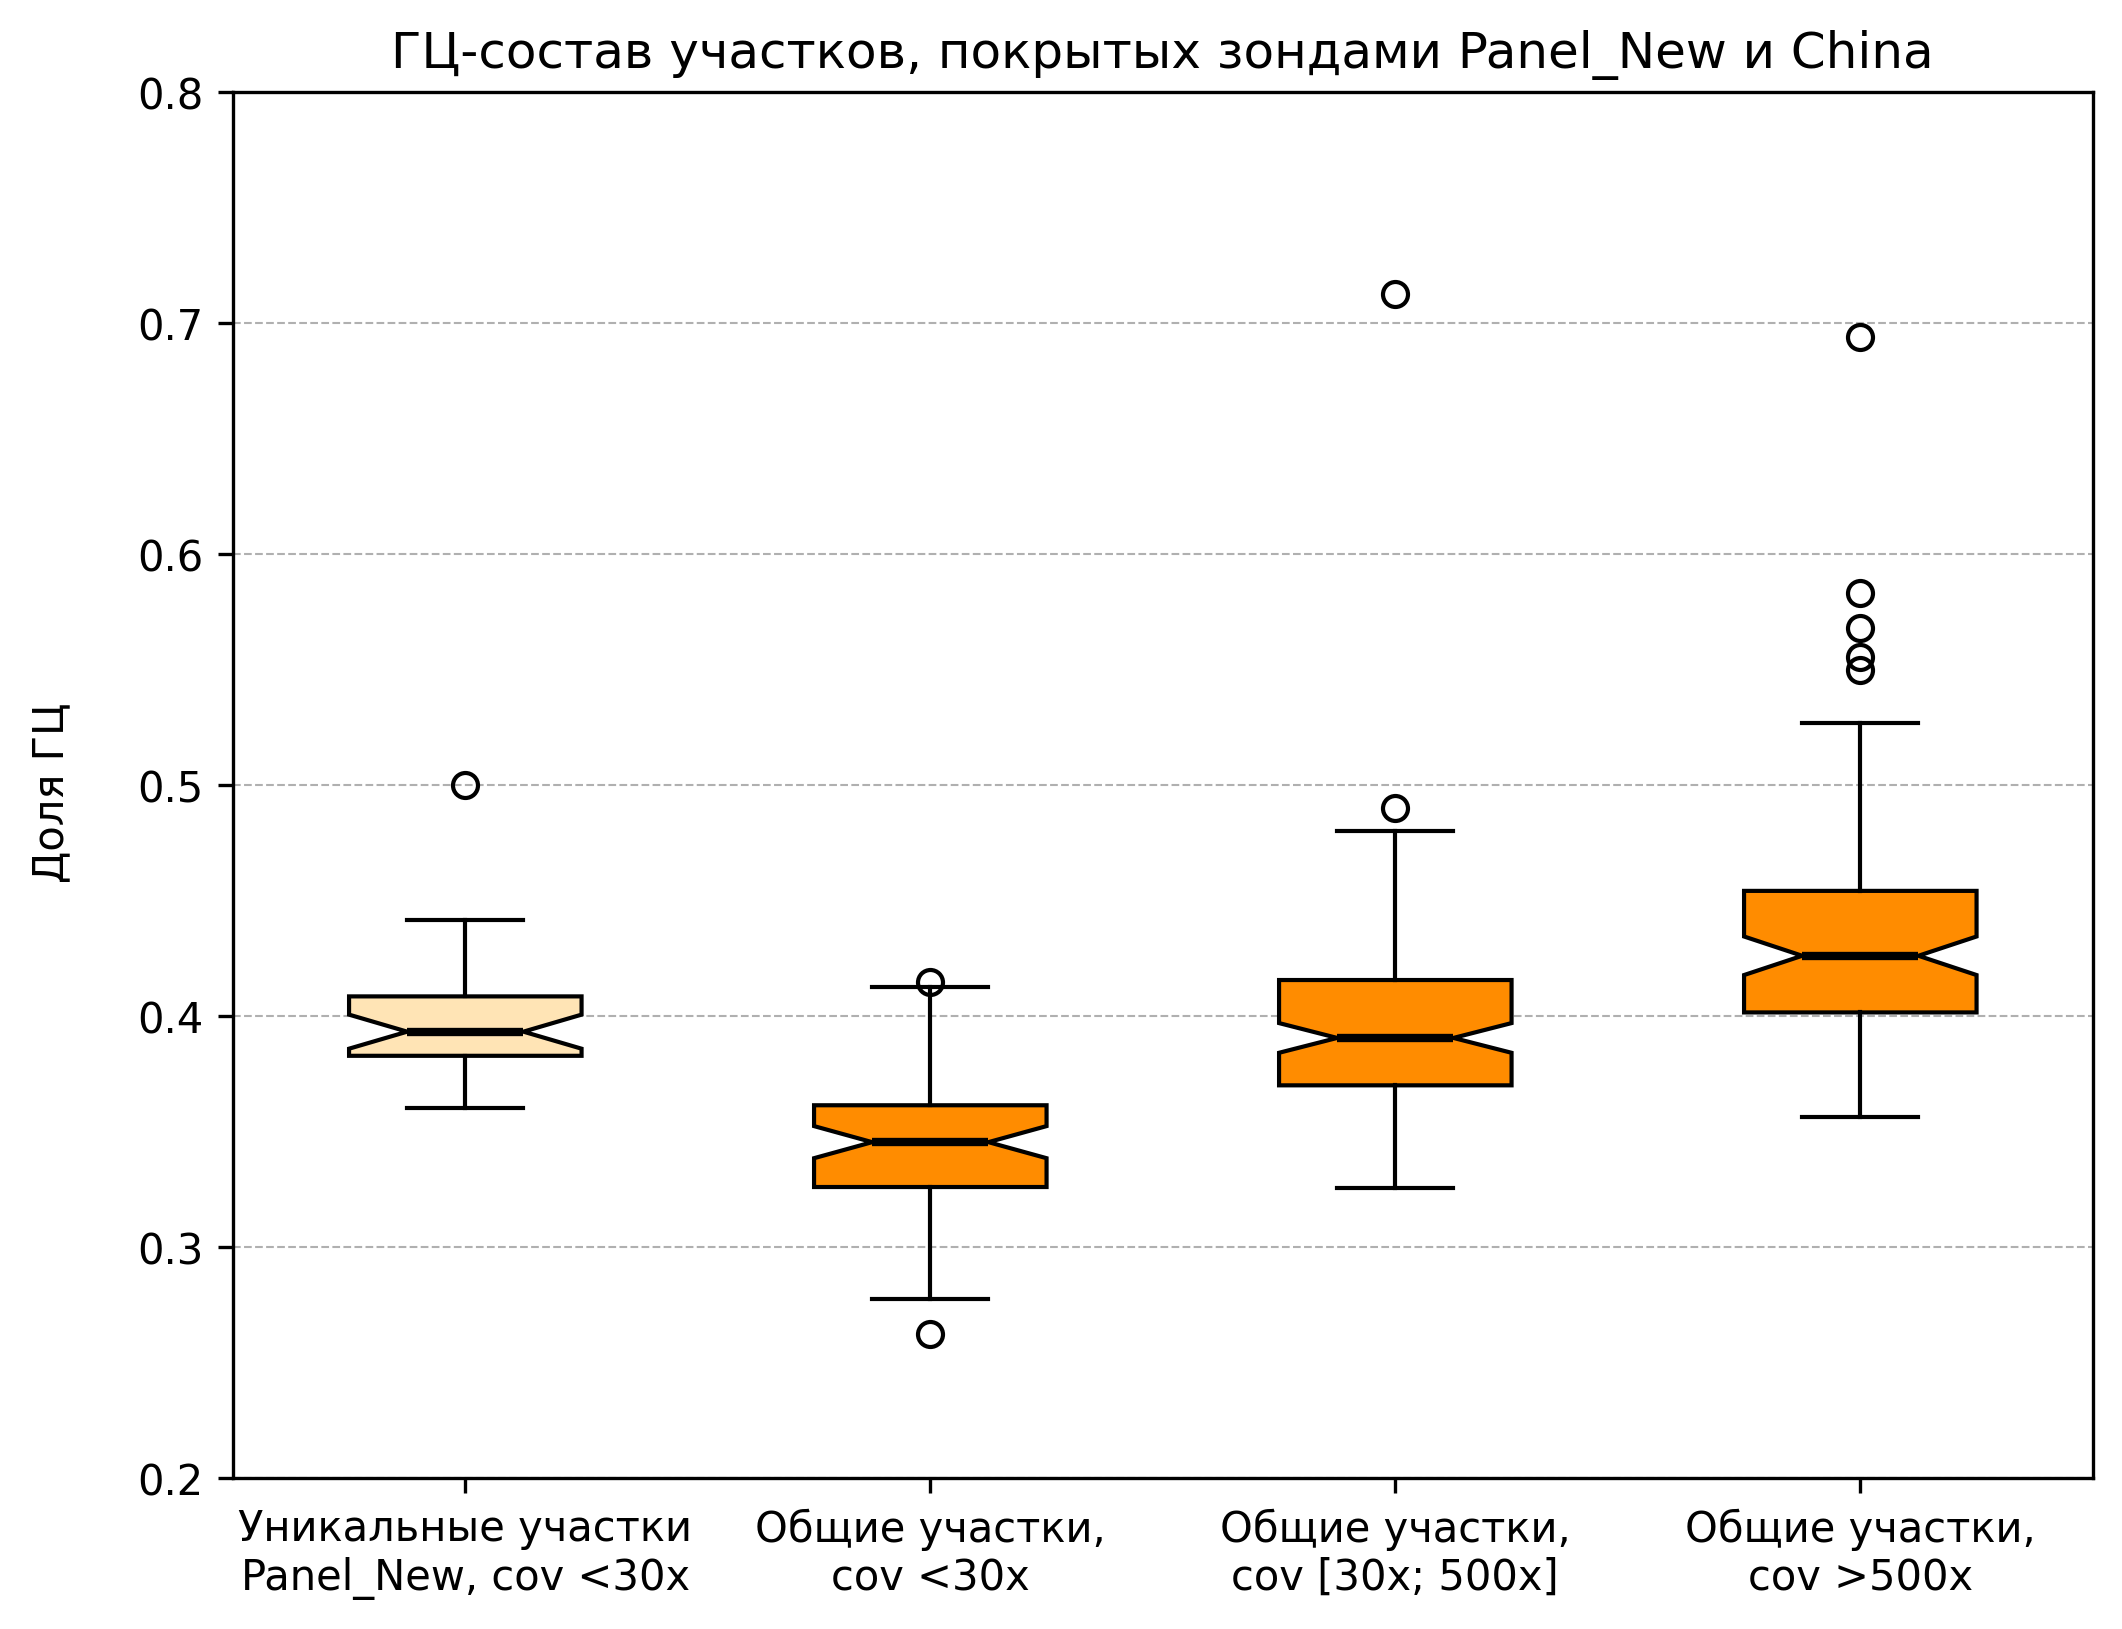

In [ ]:
fig, ax = plt.subplots(figsize=(8,6), dpi=300)
colors = ['moccasin', 'darkorange', 'darkorange', 'darkorange']
medians = dict(linewidth=2, color='black')
ticks = [f'Уникальные участки\nPanel_New, cov <30x',
         f'Общие участки,\ncov <30x',
         f'Общие участки,\ncov [30x; 500x]',
         f'Общие участки,\ncov >500x']

bplot = ax.boxplot([df.iloc[:30,0], df.iloc[:64,1], df.iloc[:124,2], df.iloc[:98,3]], 
                   patch_artist=True, tick_labels=ticks,
                   widths=0.5, medianprops=medians,
                   notch=True)
for patch, color in zip(bplot['boxes'], colors):
    patch.set_facecolor(color)

plt.yticks(np.arange(0.2, 0.8, 0.1))
ax.yaxis.grid(True, linestyle='--', linewidth=0.5)
ax.set_ylabel(f"Доля ГЦ \n")
ax.set_title("ГЦ-состав участков, покрытых зондами Panel_New и China")
#plt.savefig("GC_unique_low_mod_high.png")

Text(0, 0.5, 'Доля ГЦ \n')

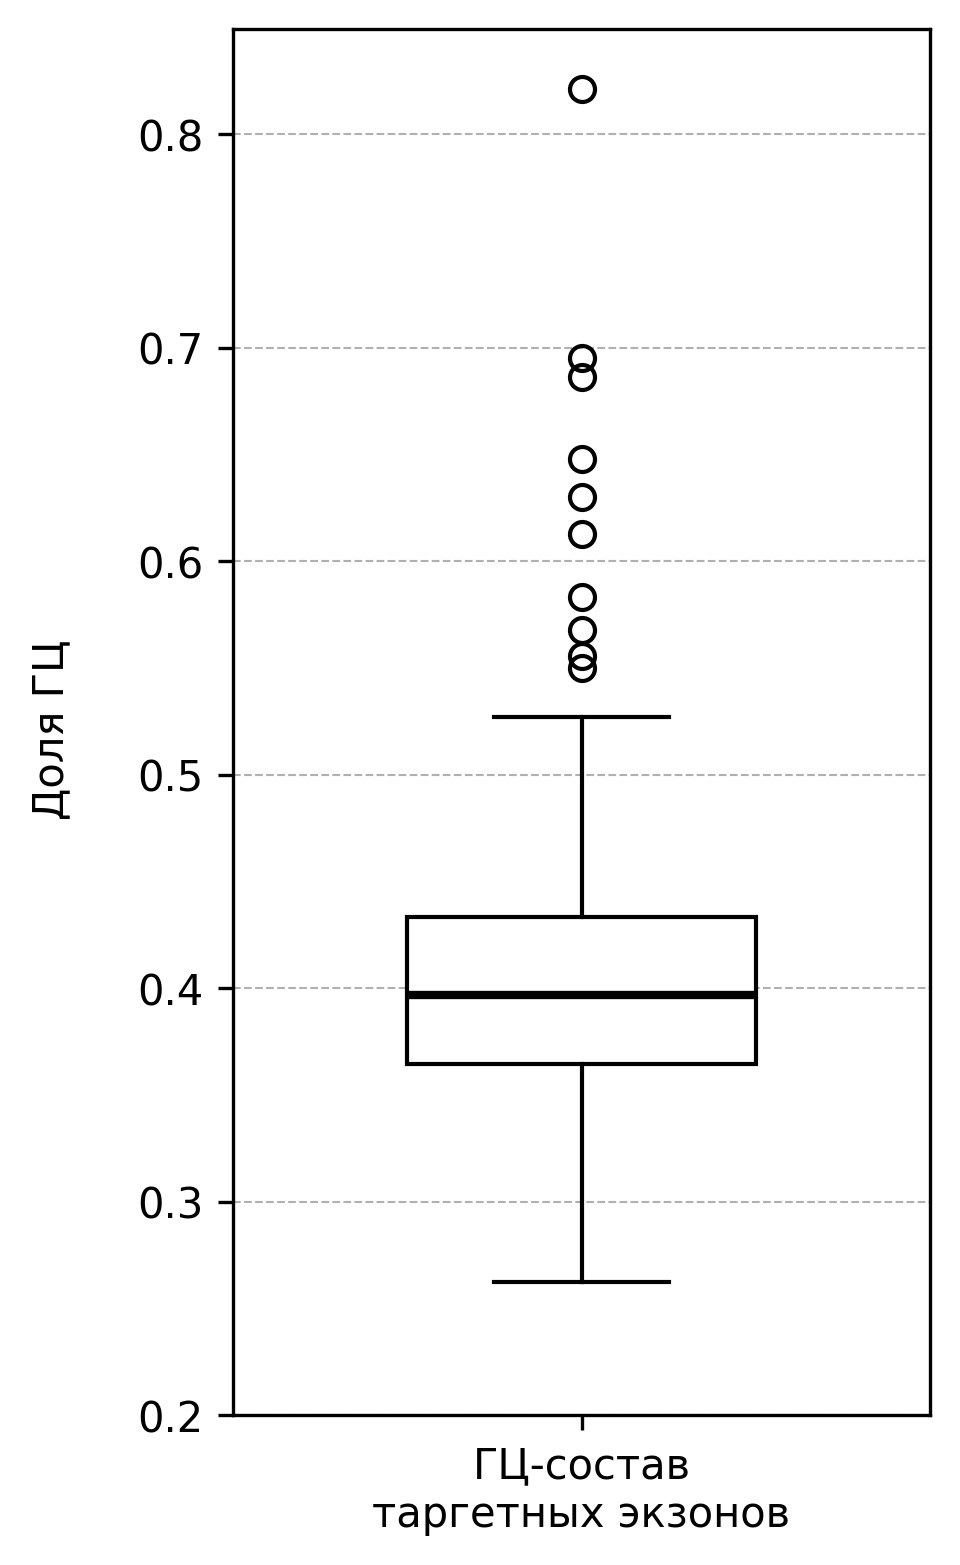

In [ ]:
fig, ax = plt.subplots(figsize=(3,6), dpi=300)
colors = ['white']
medians = dict(linewidth=2, color='black')
ticks = [f'ГЦ-состав\nтаргетных экзонов']

bplot = ax.boxplot([df.iloc[:,4]], 
                   patch_artist=True, tick_labels=ticks,
                   widths=0.5, medianprops=medians)
for patch, color in zip(bplot['boxes'], colors):
    patch.set_facecolor(color)

plt.yticks(np.arange(0.2, 0.8, 0.1))
ax.yaxis.grid(True, linestyle='--', linewidth=0.5)
ax.set_ylabel(f"Доля ГЦ \n")
#plt.savefig("GC_exons.png")

In [ ]:
stats = boxplot_stats([df.iloc[:30,0], df.iloc[:64,1], df.iloc[:124,2], df.iloc[:98,3]])

# 'stats' is a list of dictionaries (one for each data series)
for s in stats:
    print(f"Median: {s['med']:.2f}")
    print(f"95% CI: [{s['cilo']:.2f}, {s['cihi']:.2f}]")

Median: 0.39
95% CI: [0.39, 0.40]
Median: 0.35
95% CI: [0.34, 0.35]
Median: 0.39
95% CI: [0.38, 0.40]
Median: 0.43
95% CI: [0.42, 0.43]
